# Lab 2 — Time-Series Stock Forecasting with RNN / LSTM / GRU
### ASML daily Close: recurrent networks vs naïve, moving-average, ARIMA and Prophet baselines

*Educational use only - not financial advice.*



| Section | Contents |
|---|---|
| 1 | Introduction and research questions |
| 2 | Data acquisition and documentation |
| 3 | Preprocessing and feature engineering |
| 4 | Baselines (naïve, moving average, ARIMA, Prophet) |
| 5 | Model architectures (RNN / LSTM / GRU) |
| 6 | Training protocol |
| 7 | Experiments and ablations |
| 8 | Results and visualizations |
| 9 | Error analysis |
| 10 | Conclusions and lessons learned |
| 11 | Reproducibility notes and deliverables |

## 1. Introduction and Research Questions
**Task.** Forecast ASML's closing price over the next 5 trading days.

**Research questions**
1. Can RNN, LSTM and GRU beat naïve and moving-average baselines for a 5-day horizon?
2. Do technical indicators and market covariates (SOX, SPY, VIX) help compared with returns only?
3. How sensitive are the results to lookback window, hidden size and forecast horizon?
4. Do errors cluster in high-volatility regimes?

### 1.1 Setup: installs

In [ ]:
!pip -q install yfinance prophet statsmodels mplfinance scipy scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.0/75.0 kB 5.0 MB/s eta 0:00:00


### 1.2 Imports, seeds and versions

In [ ]:
import os, re, json, random, shutil, warnings, logging
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import mplfinance as mpf
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
from scipy import stats
from tqdm.auto import tqdm
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf

warnings.filterwarnings("ignore")
logging.getLogger("cmdstanpy").setLevel(logging.ERROR)
logging.getLogger("prophet").setLevel(logging.ERROR)

SEED = 42
def seed_all(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
seed_all()

device = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| CUDA", torch.version.cuda, "| cuDNN", torch.backends.cudnn.version(), "| device:", device)

torch 2.11.0+cu130 | CUDA 13.0 | cuDNN 92700 | device: cuda


### 1.3 Workspace (Google Drive)


In [ ]:
USE_DRIVE = True
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    WORKDIR = "/content/drive/MyDrive/asml_lab2_final"
    os.makedirs(WORKDIR, exist_ok=True); os.chdir(WORKDIR)
os.makedirs("ckpt", exist_ok=True)
print("Working in:", os.getcwd())

Mounted at /content/drive
Working in: /content/drive/MyDrive/asml_lab2_final


## 2. Data Acquisition and Documentation
**Source:** Yahoo Finance via `yfinance` (ASML, daily OHLCV, from 2015) plus ^SOX, SPY and ^VIX as covariates. Data are cached as CSV for reproducibility.

In [ ]:
TICKER, CSV, EXT_CSV = "ASML", "asml_daily.csv", "ext_daily.csv"
if os.path.exists(CSV):
    df = pd.read_csv(CSV, index_col=0, parse_dates=True)
else:
    import yfinance as yf
    raw = yf.download(TICKER, start="2015-01-01", auto_adjust=False, progress=False)
    if isinstance(raw.columns, pd.MultiIndex): raw.columns = raw.columns.get_level_values(0)
    df = raw[["Open", "High", "Low", "Close", "Volume"]].dropna()
    df.index = pd.to_datetime(df.index).tz_localize(None)
    df.to_csv(CSV)

if os.path.exists(EXT_CSV):
    ext = pd.read_csv(EXT_CSV, index_col=0, parse_dates=True)
else:
    import yfinance as yf
    ext = yf.download(["^SOX", "SPY", "^VIX"], start="2015-01-01", auto_adjust=False, progress=False)["Close"]
    ext.index = pd.to_datetime(ext.index).tz_localize(None)
    ext.to_csv(EXT_CSV)

close = df["Close"].astype(float)
print(f"{TICKER}: {df.shape[0]} trading days, {df.index.min().date()} -> {df.index.max().date()}")

data_dictionary = pd.DataFrame({
    "field": ["Date", "Open", "High", "Low", "Close", "Volume", "^SOX", "SPY", "^VIX"],
    "description": ["Trading day (index)", "Opening price (USD)", "Daily high (USD)", "Daily low (USD)",
                    "Closing price (USD), the forecast target", "Shares traded",
                    "PHLX Semiconductor index close (sector signal)", "S&P 500 ETF close (market signal)",
                    "CBOE volatility index close (risk signal)"],
    "source": ["Yahoo Finance via yfinance"] * 9})
display(data_dictionary)
df.tail()

ASML: 2967 trading days, 2015-01-02 -> 2026-10-20


,field,description,source
0,Date,Trading day (index),Yahoo Finance via yfinance
1,Open,Opening price (USD),Yahoo Finance via yfinance
2,High,Daily high (USD),Yahoo Finance via yfinance
3,Low,Daily low (USD),Yahoo Finance via yfinance
4,Close,"Closing price (USD), the forecast target",Yahoo Finance via yfinance
5,Volume,Shares traded,Yahoo Finance via yfinance
6,^SOX,PHLX Semiconductor index close (sector signal),Yahoo Finance via yfinance
7,SPY,S&P 500 ETF close (market signal),Yahoo Finance via yfinance
8,^VIX,CBOE volatility index close (risk signal),Yahoo Finance via yfinance


,Open,High,Low,Close,Volume
Date,,,,,
2026-10-14,1676.800049,1734.500000,1648.800049,1650.000000,2877200
2026-10-15,1616.140015,1661.140015,1594.030029,1657.439941,1984700
2026-10-16,1659.010010,1686.319946,1639.430054,1641.520020,1887700
2026-10-19,1678.750000,1681.780029,1646.020020,1647.119995,1256200
2026-10-20,1633.660034,1654.209961,1613.540039,1630.839966,990600


## 3. Preprocessing and Feature Engineering
### 3.1 Chronological split (70 / 15 / 15) and required visualizations
Close price with shaded splits, indicator overlays (SMA, Bollinger Bands, RSI, MACD) and candlesticks.

train: 2015-01-02 -> 2023-03-31
val  : 2023-04-03 -> 2025-01-08
test : 2025-01-10 -> 2026-10-20


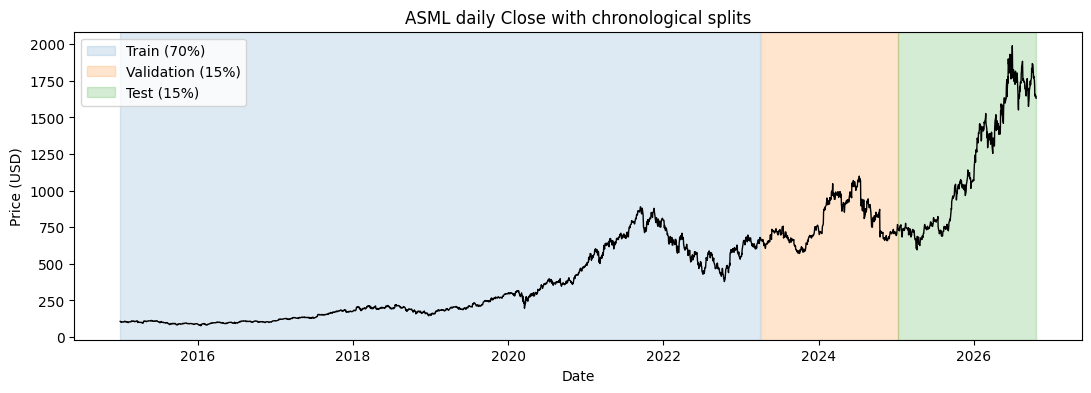

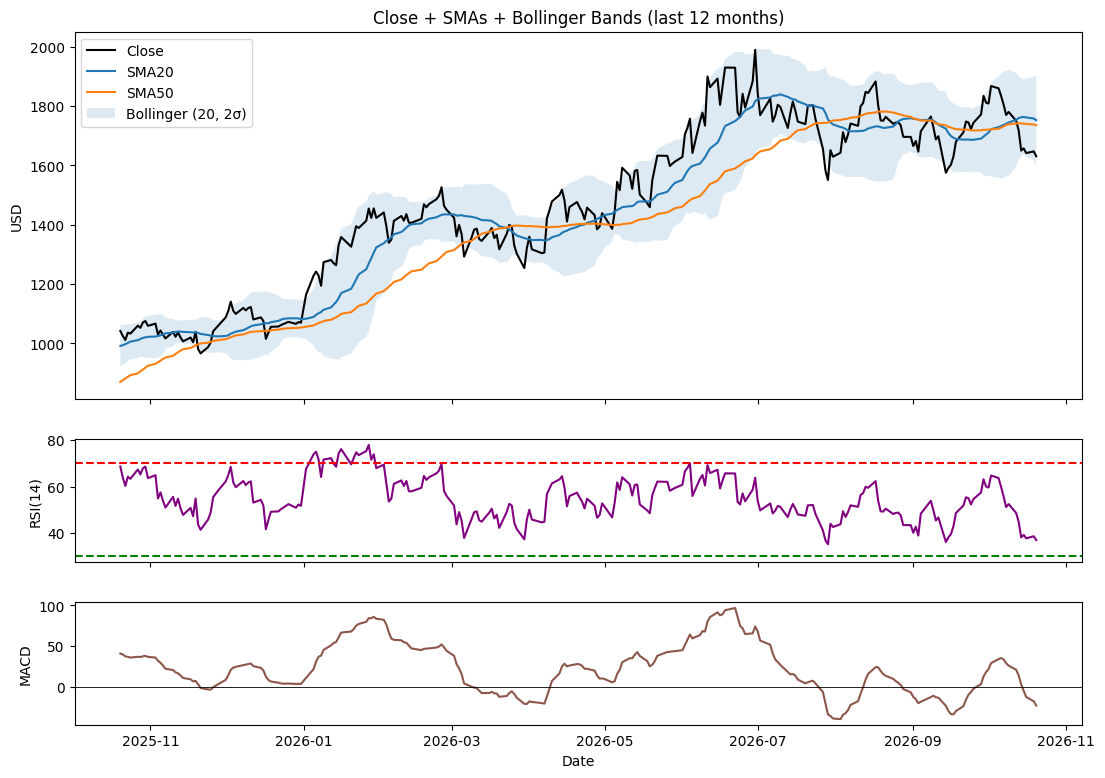

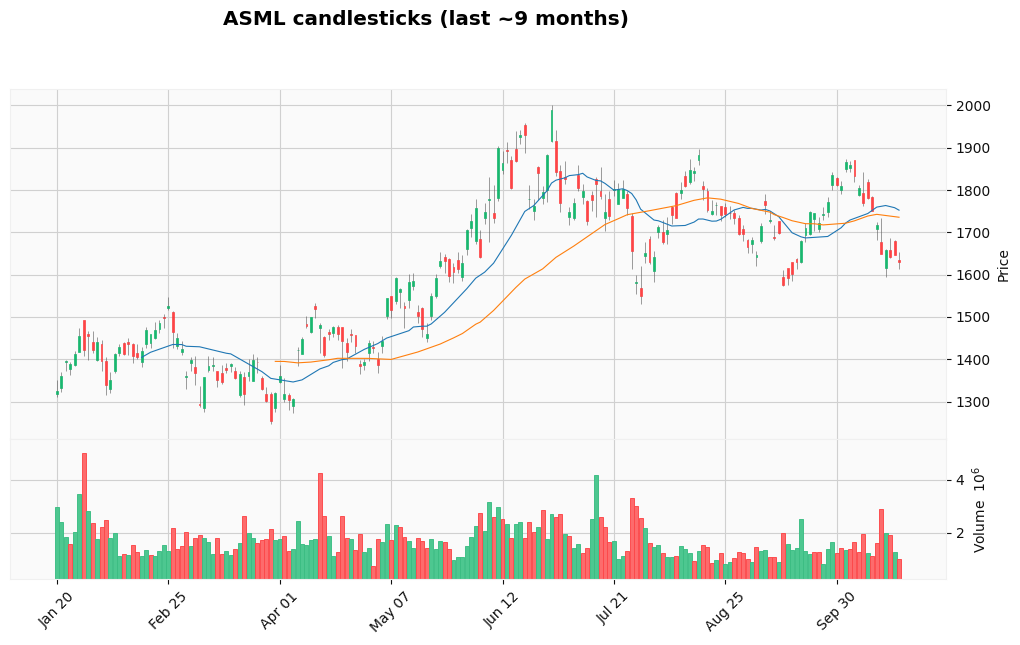

In [ ]:
n = len(df)
TRAIN_END, VAL_END = int(0.70 * n), int(0.85 * n)
print("train:", df.index[0].date(), "->", df.index[TRAIN_END-1].date())
print("val  :", df.index[TRAIN_END].date(), "->", df.index[VAL_END-1].date())
print("test :", df.index[VAL_END].date(), "->", df.index[-1].date())

def add_indicators(d):
    c, out = d["Close"], d.copy()
    out["SMA20"], out["SMA50"] = c.rolling(20).mean(), c.rolling(50).mean()
    sd = c.rolling(20).std()
    out["BB_up"], out["BB_lo"] = out["SMA20"] + 2*sd, out["SMA20"] - 2*sd
    delta = c.diff()
    up = delta.clip(lower=0).ewm(alpha=1/14, adjust=False).mean()
    dn = (-delta.clip(upper=0)).ewm(alpha=1/14, adjust=False).mean()
    out["RSI14"] = 100 - 100 / (1 + up / dn)
    out["MACD"] = c.ewm(span=12, adjust=False).mean() - c.ewm(span=26, adjust=False).mean()
    return out

ind = add_indicators(df)

# (a) Close price with shaded splits
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(close.index, close, lw=1, color="black")
ax.axvspan(df.index[0], df.index[TRAIN_END-1], color="tab:blue", alpha=.15, label="Train (70%)")
ax.axvspan(df.index[TRAIN_END], df.index[VAL_END-1], color="tab:orange", alpha=.2, label="Validation (15%)")
ax.axvspan(df.index[VAL_END], df.index[-1], color="tab:green", alpha=.2, label="Test (15%)")
ax.set(title=f"{TICKER} daily Close with chronological splits", xlabel="Date", ylabel="Price (USD)"); ax.legend()
plt.show()

# (b) Indicator overlays (last 12 months)
last = ind.iloc[-252:]
fig, (a1, a2, a3) = plt.subplots(3, 1, figsize=(13, 9), sharex=True, gridspec_kw={"height_ratios": [3, 1, 1]})
a1.plot(last.index, last["Close"], color="black", label="Close")
a1.plot(last.index, last["SMA20"], label="SMA20"); a1.plot(last.index, last["SMA50"], label="SMA50")
a1.fill_between(last.index, last["BB_lo"], last["BB_up"], alpha=.15, label="Bollinger (20, 2σ)")
a1.set(title="Close + SMAs + Bollinger Bands (last 12 months)", ylabel="USD"); a1.legend()
a2.plot(last.index, last["RSI14"], color="purple"); a2.axhline(70, ls="--", c="r"); a2.axhline(30, ls="--", c="g"); a2.set_ylabel("RSI(14)")
a3.plot(last.index, last["MACD"], color="tab:brown"); a3.axhline(0, c="k", lw=.6); a3.set(ylabel="MACD", xlabel="Date")
plt.show()

# (c) Candlesticks (last ~9 months)
mpf.plot(df.iloc[-190:], type="candle", mav=(20, 50), volume=True, style="yahoo",
         figsize=(13, 7), title=f"{TICKER} candlesticks (last ~9 months)")

### 3.2 Feature engineering, scaling (train only) and windowing
All features are causal. `StandardScaler` and the target scale are fit on training rows only. Univariate = log-return only; multivariate = 12 features.

In [ ]:
def build_features(d, ext_df):
    """All features are causal: row t only uses information available at the close of day t."""
    ind_ = add_indicators(d); c = d["Close"]
    e = ext_df.reindex(d.index).ffill()
    F_ = pd.DataFrame(index=d.index)
    F_["ret"]    = np.log(c).diff()
    F_["hl"]     = np.log(d["High"] / d["Low"])
    F_["dvol"]   = np.log(d["Volume"].replace(0, np.nan)).diff().clip(-2, 2)
    F_["rsi"]    = ind_["RSI14"] / 100
    F_["macd"]   = ind_["MACD"] / c
    F_["sma20"]  = np.log(c / ind_["SMA20"])
    F_["sma50"]  = np.log(c / ind_["SMA50"])
    F_["vol20"]  = F_["ret"].rolling(20).std()                         # rolling volatility
    F_["sox"]    = np.log(e["^SOX"]).diff()
    F_["spy"]    = np.log(e["SPY"]).diff()
    F_["vix"]    = np.log(e["^VIX"]).diff()
    F_["vixlvl"] = np.log(e["^VIX"])
    return F_.replace([np.inf, -np.inf], np.nan)

F = build_features(df, ext)
FEATS = {"uni": ["ret"], "multi": list(F.columns)}        # univariate vs multivariate configurations

H_MAIN, STEP = 5, 5                                       # forecast horizon and gap between walk-forward origins
LOOKBACKS = [30, 60, 120]
FV = int(F[FEATS["multi"]].notna().all(axis=1).values.argmax())   # first row where every feature exists
START = FV + max(LOOKBACKS)                               # same samples for every lookback -> comparable losses
LOGC = np.log(close.values)

# Scaling: StandardScaler fit ONLY on training rows
SC, SCALERS = {}, {}
for k, cols in FEATS.items():
    sc = StandardScaler().fit(F[cols].iloc[FV:TRAIN_END])
    SCALERS[k] = sc
    SC[k] = sc.transform(F[cols].fillna(0)).astype(np.float32)

def split_ends(H):
    """Window end-indices t: input = rows [t-L, t), target = closes t..t+H-1, fully inside the split."""
    return list(range(START, TRAIN_END - H + 1)), list(range(TRAIN_END, VAL_END - H + 1))

def target_sd(H):
    """Std of the training targets (log-return paths), used to scale y. Train data only."""
    tr, _ = split_ends(H)
    return float(np.stack([LOGC[t:t+H] - LOGC[t-1] for t in tr]).std())

tr_e, va_e = split_ends(H_MAIN)
print(f"features: uni={len(FEATS['uni'])}, multi={len(FEATS['multi'])} | first full-feature row={FV} | "
      f"train windows={len(tr_e)}, val windows={len(va_e)} | target std={target_sd(H_MAIN):.4f}")

features: uni=1, multi=12 | first full-feature row=49 | train windows=1903, val windows=441 | target std=0.0385


## 4. Baselines
Naïve (last value), simple moving averages, and ARIMA / Prophet as optional references, all evaluated with the same rolling-origin (expanding-window) engine. MAPE uses a near-zero safeguard.

In [ ]:
def naive(hist, fdates):
    return np.repeat(hist.iloc[-1], len(fdates))

def make_ma(w):
    return lambda hist, fdates: np.repeat(hist.iloc[-w:].mean(), len(fdates))

def make_arima(order=(1, 1, 1)):                            # optional reference (log-price, drift)
    def f(hist, fdates):
        m = ARIMA(np.log(hist.values[-1000:]), order=order, trend="t").fit()
        return np.exp(m.forecast(len(fdates)))
    return f

def make_prophet(cps=0.05):                                 # optional reference (log-price, last ~3 years)
    from prophet import Prophet
    def f(hist, fdates):
        h = hist.iloc[-756:]
        d = pd.DataFrame({"ds": h.index, "y": np.log(h.values)})
        m = Prophet(daily_seasonality=False, weekly_seasonality=False, yearly_seasonality=True,
                    changepoint_prior_scale=cps).fit(d)
        return np.exp(m.predict(pd.DataFrame({"ds": fdates}))["yhat"].values)
    return f

def walk_forward(fc, start, end, H=H_MAIN, step=None, desc=""):
    """Rolling-origin (expanding window): the forecast made at origin t only sees close[:t]."""
    step, recs = step or H, []
    for t in tqdm(range(start, end - H + 1, step), desc=desc, leave=False):
        hist, fd = close.iloc[:t], close.index[t:t+H]
        pred = np.asarray(fc(hist, fd), dtype=float)
        for k in range(H):
            recs.append(dict(origin=close.index[t-1], date=fd[k], h=k+1,
                             y=close.iloc[t+k], yhat=pred[k], last=close.iloc[t-1]))
    return pd.DataFrame(recs)

def metrics(r):
    e = r["y"] - r["yhat"]
    mv = r["yhat"] != r["last"]                       # direction is undefined when forecast == last close (naive)
    hit = np.sign(r["yhat"] - r["last"]) == np.sign(r["y"] - r["last"])
    return dict(MAE=e.abs().mean(),
                RMSE=np.sqrt((e**2).mean()),
                MAPE=(e.abs() / r["y"].abs().clip(lower=1e-8)).mean() * 100,     # safeguard near zero
                DirAcc=hit[mv].mean() * 100 if mv.any() else np.nan)

def fold_rmse(run):
    return np.sqrt(((run["y"] - run["yhat"])**2).groupby(run["origin"]).mean())

## 5. Model Architectures
Following the course tutorials: `nn.RNN`, `nn.LSTM`, `nn.GRU` + `Linear` head. Many-to-one: the last layer's final hidden state `h_n[-1]` predicts the next 5 log-return steps, converted back to prices.

In [ ]:
class StockWindowDataset(Dataset):
    """X_window = last L feature rows before day t ; y_target = log(close[t..t+H-1] / close[t-1]) / ysd."""
    def __init__(self, X, logc, ends, L, H, ysd):
        self.X, self.logc, self.ends, self.L, self.H, self.ysd = X, logc, ends, L, H, ysd
    def __len__(self):
        return len(self.ends)
    def __getitem__(self, idx):
        t = self.ends[idx]
        x = torch.from_numpy(self.X[t - self.L:t])                                   # (L, n_features)
        y = (self.logc[t:t + self.H] - self.logc[t - 1]) / self.ysd                   # (H,)
        return x, torch.from_numpy(y.astype(np.float32))

class RNNForecaster(nn.Module):
    def __init__(self, input_size, hidden_size=64, num_layers=2, dropout=0.2, horizon=5):
        super().__init__()
        self.rnn = nn.RNN(input_size, hidden_size, num_layers=num_layers, batch_first=True,
                          dropout=dropout if num_layers > 1 else 0.0)
        self.drop, self.fc = nn.Dropout(dropout), nn.Linear(hidden_size, horizon)
    def forward(self, x):                      # x: (B, L, F)
        out, h_n = self.rnn(x)                 # h_n: (layers, B, H)
        return self.fc(self.drop(h_n[-1]))     # many-to-one: last layer's final hidden state -> H outputs

class LSTMForecaster(nn.Module):
    def __init__(self, input_size, hidden_size=64, num_layers=2, dropout=0.2, horizon=5):
        super().__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers=num_layers, batch_first=True,
                            dropout=dropout if num_layers > 1 else 0.0)
        self.drop, self.fc = nn.Dropout(dropout), nn.Linear(hidden_size, horizon)
    def forward(self, x):
        out, (h_n, c_n) = self.lstm(x)
        return self.fc(self.drop(h_n[-1]))

class GRUForecaster(nn.Module):
    def __init__(self, input_size, hidden_size=64, num_layers=2, dropout=0.2, horizon=5):
        super().__init__()
        self.gru = nn.GRU(input_size, hidden_size, num_layers=num_layers, batch_first=True,
                          dropout=dropout if num_layers > 1 else 0.0)
        self.drop, self.fc = nn.Dropout(dropout), nn.Linear(hidden_size, horizon)
    def forward(self, x):
        out, h_n = self.gru(x)
        return self.fc(self.drop(h_n[-1]))

ARCH = {"RNN": RNNForecaster, "LSTM": LSTMForecaster, "GRU": GRUForecaster}

## 6. Training Protocol
Adam + MSE, `ReduceLROnPlateau`, early stopping on validation loss (patience 10), best-checkpoint saving with `torch.save`, CSV experiment logger, automatic reload of finished runs.

### 6.1 Training functions and smoke test

In [ ]:
def make_tag(cell, fset, L, hidden, H):
    return f"{cell}_{fset}_L{L}_h{hidden}" + ("" if H == H_MAIN else f"_H{H}")

def evaluate(model, loader, loss_fn, ysd):
    """Returns (scaled MSE, MAE as % of price). Same role as the teacher's evaluate()."""
    model.eval(); tot = ab = 0.0; cnt = els = 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            pred = model(xb)
            tot += loss_fn(pred, yb).item() * xb.size(0); cnt += xb.size(0)
            ab += (pred - yb).abs().sum().item();         els += yb.numel()
    return tot / cnt, ab / els * ysd * 100

def train_model(cell, fset, L=60, H=H_MAIN, hidden=64, layers=2, dropout=0.2, lr=1e-3, bs=64,
                max_epochs=100, patience=10, tag=None):
    os.makedirs("ckpt", exist_ok=True)
    tag = tag or make_tag(cell, fset, L, hidden, H)
    seed_all()
    X, ysd = SC[fset], target_sd(H)
    tr_e, va_e = split_ends(H)
    train_loader = DataLoader(StockWindowDataset(X, LOGC, tr_e, L, H, ysd), batch_size=bs, shuffle=True)
    val_loader   = DataLoader(StockWindowDataset(X, LOGC, va_e, L, H, ysd), batch_size=256)

    model = ARCH[cell](X.shape[1], hidden, layers, dropout, H).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=0.5, patience=4)
    loss_fn = nn.MSELoss()

    cfg = dict(tag=tag, cell=cell, fset=fset, cols=FEATS[fset], L=L, H=H, hidden=hidden, layers=layers,
               dropout=dropout, lr=lr, ysd=ysd, mean=SCALERS[fset].mean_.tolist(),
               scale=SCALERS[fset].scale_.tolist(), params=sum(p.numel() for p in model.parameters()))
    path, best, wait, rows = f"ckpt/{tag}.pt", float("inf"), 0, []

    for epoch in range(1, max_epochs + 1):
        model.train(); run = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            run += loss.item() * xb.size(0)
        val_loss, val_mae = evaluate(model, val_loader, loss_fn, ysd)
        sched.step(val_loss)
        rows.append(dict(epoch=epoch, train_loss=run / len(train_loader.dataset), val_loss=val_loss,
                         val_MAE_pct=val_mae, lr=opt.param_groups[0]["lr"]))
        if val_loss < best - 1e-5:                       # best checkpoint
            best, wait = val_loss, 0
            torch.save({"state": model.state_dict(), "cfg": cfg}, path)
        else:                                            # early stopping on validation loss
            wait += 1
            if wait >= patience: break

    model.load_state_dict(torch.load(path, map_location=device, weights_only=False)["state"]); model.eval()
    hist = pd.DataFrame(rows); hist.to_csv(f"ckpt/{tag}_log.csv", index=False)
    cfg.update(best_val_loss=best, epochs=len(hist), best_val_MAE_pct=float(hist.val_MAE_pct.min()))
    log = {k: v for k, v in cfg.items() if k not in ("cols", "mean", "scale")}                # lightweight logger
    pd.DataFrame([log]).to_csv("experiments.csv", mode="a", header=not os.path.exists("experiments.csv"), index=False)
    return model, hist, cfg

def load_trained(tag):
    """Reload a finished run from Drive/disk (weights + log) instead of training it again."""
    ck = torch.load(f"ckpt/{tag}.pt", map_location=device, weights_only=False); c = ck["cfg"]
    m = ARCH[c["cell"]](len(c["cols"]), c["hidden"], c["layers"], c["dropout"], c["H"]).to(device)
    m.load_state_dict(ck["state"]); m.eval()
    h = pd.read_csv(f"ckpt/{tag}_log.csv")
    c.update(best_val_loss=float(h.val_loss.min()), epochs=len(h), best_val_MAE_pct=float(h.val_MAE_pct.min()))
    return m, h, c

RETRAIN = False       # True = ignore saved checkpoints and train everything again
DL, HIST, CFG = {}, {}, {}
def get_model(cell, fset, L=60, hidden=64, H=H_MAIN, **kw):
    tag = make_tag(cell, fset, L, hidden, H)
    if tag not in DL:
        if not RETRAIN and os.path.exists(f"ckpt/{tag}.pt") and os.path.exists(f"ckpt/{tag}_log.csv"):
            DL[tag], HIST[tag], CFG[tag] = load_trained(tag)
        else:
            DL[tag], HIST[tag], CFG[tag] = train_model(cell, fset, L=L, hidden=hidden, H=H, tag=tag, **kw)
    return tag

# smoke test (about 1 minute): one univariate LSTM
t0 = get_model("LSTM", "uni"); print(t0, "| epochs:", CFG[t0]["epochs"], "| best val loss:", round(CFG[t0]["best_val_loss"], 4))

LSTM_uni_L60_h64 | epochs: 14 | best val loss: 1.1389


## 7. Experiments and Ablations
### 7.1 Grid: 3 architectures × 2 feature sets, with training curves

architectures:   0%|          | 0/3 [00:00<?, ?it/s]

,cell,fset,params,epochs,best_val_loss,best_val_MAE_pct
0,RNN,uni,12933,13,1.1431,2.8275
1,RNN,multi,13637,11,1.1509,2.8469
2,LSTM,uni,50757,14,1.1389,2.8259
3,LSTM,multi,53573,12,1.1439,2.8342
4,GRU,uni,38149,12,1.1401,2.8267
5,GRU,multi,40261,17,1.1349,2.8366


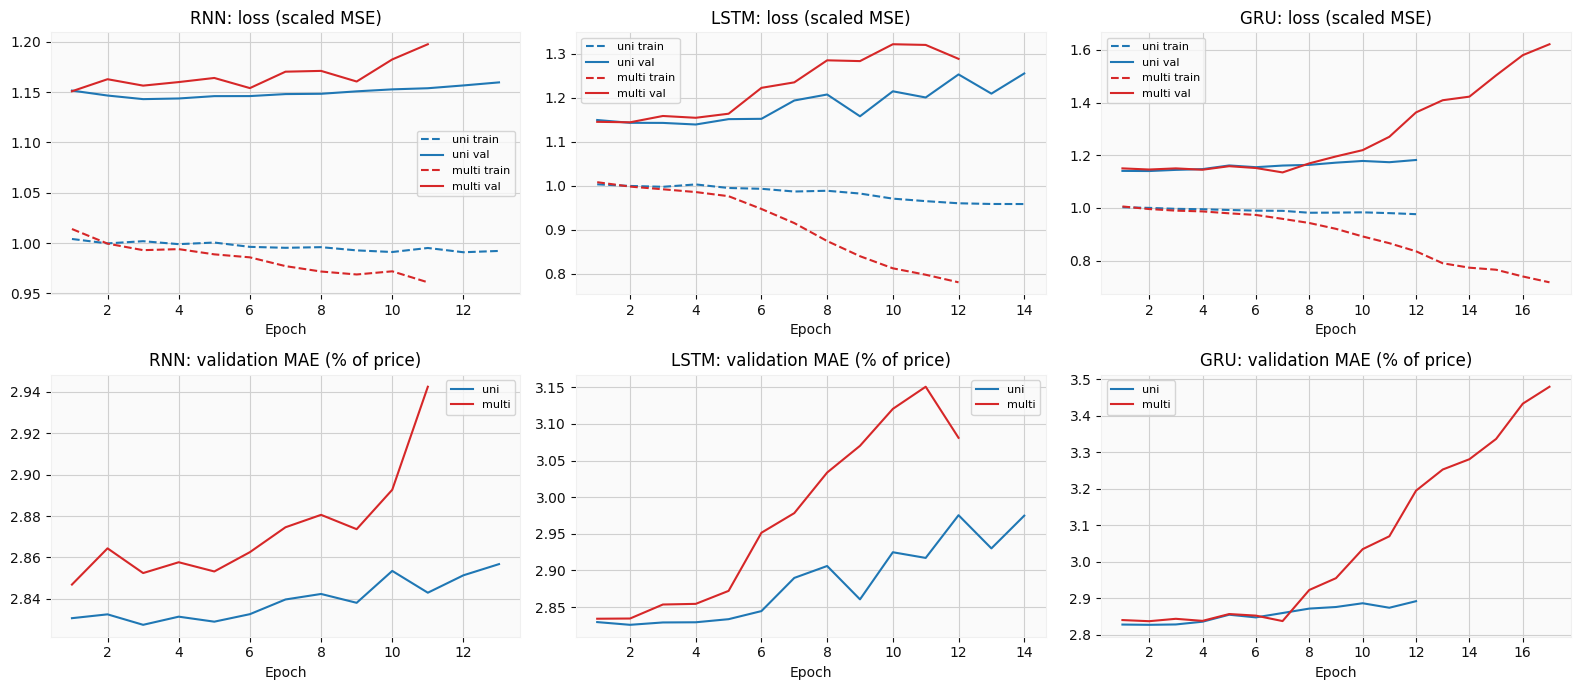

In [ ]:
CELLS, FSETS = ["RNN", "LSTM", "GRU"], ["uni", "multi"]
for c in tqdm(CELLS, desc="architectures"):
    for f in FSETS:
        get_model(c, f)

grid = pd.DataFrame([CFG[make_tag(c, f, 60, 64, H_MAIN)] for c in CELLS for f in FSETS])
display(grid[["cell", "fset", "params", "epochs", "best_val_loss", "best_val_MAE_pct"]].round(4))

fig, axes = plt.subplots(2, 3, figsize=(16, 7), sharex=False)
for j, c in enumerate(CELLS):
    for f, col in zip(FSETS, ["tab:blue", "tab:red"]):
        h = HIST[make_tag(c, f, 60, 64, H_MAIN)]
        axes[0, j].plot(h.epoch, h.train_loss, "--", color=col, label=f"{f} train")
        axes[0, j].plot(h.epoch, h.val_loss, color=col, label=f"{f} val")
        axes[1, j].plot(h.epoch, h.val_MAE_pct, color=col, label=f"{f}")
    axes[0, j].set(title=f"{c}: loss (scaled MSE)", xlabel="Epoch"); axes[0, j].legend(fontsize=8)
    axes[1, j].set(title=f"{c}: validation MAE (% of price)", xlabel="Epoch"); axes[1, j].legend(fontsize=8)
plt.tight_layout(); plt.show()

### 7.2 Ablations (validation only): lookback, hidden size, forecast horizon

In [ ]:
best = grid.loc[grid.best_val_loss.idxmin()]
bc, bf = best.cell, best.fset
print("Best architecture/features from the grid:", bc, bf)

for L in LOOKBACKS: get_model(bc, bf, L=L)            # lookback ablation
for hid in [32, 64, 128]: get_model(bc, bf, hidden=hid)   # capacity ablation

abl = pd.DataFrame([CFG[t] for t in DL if CFG[t]["cell"] == bc and CFG[t]["fset"] == bf and CFG[t]["H"] == H_MAIN])
display(abl[["tag", "L", "hidden", "params", "epochs", "best_val_loss", "best_val_MAE_pct"]]
        .sort_values("best_val_loss").round(4))

# overall best neural config on validation loss (all share the same validation windows and target scale)
all_h5 = pd.DataFrame([CFG[t] for t in DL if CFG[t]["H"] == H_MAIN])
final_tag = all_h5.loc[all_h5.best_val_loss.idxmin(), "tag"]
fc_ = CFG[final_tag]; print("Best neural configuration:", final_tag)

# horizon ablation for that configuration (reported vs naive at the SAME horizon; validation only)
def make_dl(tag):
    m, c = DL[tag], CFG[tag]; X, L, ysd = SC[c["fset"]], c["L"], c["ysd"]
    def f(hist, fdates):
        t = len(hist)                                        # history = close[:t] -> features up to day t-1 only
        x = torch.from_numpy(X[t - L:t]).unsqueeze(0).to(device)
        with torch.no_grad():
            out = m(x).cpu().numpy()[0] * ysd
        return hist.iloc[-1] * np.exp(out[:len(fdates)])
    return f

hz = []
for h in [1, 3, 5]:
    tg = get_model(fc_["cell"], fc_["fset"], L=fc_["L"], hidden=fc_["hidden"], H=h)
    rm = metrics(walk_forward(make_dl(tg), TRAIN_END, VAL_END, H=h))
    rn = metrics(walk_forward(naive, TRAIN_END, VAL_END, H=h))
    hz.append(dict(horizon=h, model_RMSE=rm["RMSE"], naive_RMSE=rn["RMSE"], ratio=rm["RMSE"] / rn["RMSE"], DirAcc=rm["DirAcc"]))
display(pd.DataFrame(hz).round(3))

Best architecture/features from the grid: GRU multi


,tag,L,hidden,params,epochs,best_val_loss,best_val_MAE_pct
0,GRU_multi_L60_h64,60,64,40261,17,1.1349,2.8366
1,GRU_multi_L30_h64,30,64,40261,16,1.1427,2.8348
2,GRU_multi_L120_h64,120,64,40261,15,1.1444,2.8376
3,GRU_multi_L60_h32,60,32,10917,11,1.1485,2.8423
4,GRU_multi_L60_h128,60,128,154245,11,1.1516,2.8376


Best neural configuration: GRU_multi_L60_h64


  0%|          | 0/445 [00:00<?, ?it/s]

  0%|          | 0/445 [00:00<?, ?it/s]

  0%|          | 0/148 [00:00<?, ?it/s]

  0%|          | 0/148 [00:00<?, ?it/s]

  0%|          | 0/89 [00:00<?, ?it/s]

  0%|          | 0/89 [00:00<?, ?it/s]

,horizon,model_RMSE,naive_RMSE,ratio,DirAcc
0,1,20.703,20.859,0.993,50.562
1,3,26.247,26.256,1.000,52.928
2,5,31.700,31.426,1.009,53.258


## 8. Results and Visualizations
### 8.1 Validation walk-forward and model selection
All choices are made on validation only.

In [ ]:
RUN_CLASSICAL = True

cands = {"Naive": naive}
cands.update({f"MA{w}": make_ma(w) for w in [5, 10, 20, 50]})
if RUN_CLASSICAL:
    cands["ARIMA"], cands["Prophet"] = make_arima((1, 1, 1)), make_prophet(0.05)
dl_tags = [t for t in DL if CFG[t]["H"] == H_MAIN]
cands.update({t: make_dl(t) for t in dl_tags})

val_runs = {k: walk_forward(f, TRAIN_END, VAL_END, desc=k) for k, f in cands.items()}
val_tbl = pd.DataFrame({k: metrics(v) for k, v in val_runs.items()}).T.sort_values("RMSE")
display(val_tbl.round(3).head(15))

def fam(name):
    if name in DL: return f"{CFG[name]['cell']}-{CFG[name]['fset']}"
    return re.match(r"[A-Za-z]+", name).group(0)          # Naive / MA / ARIMA / Prophet

best_per_fam = {}
for name in val_tbl.index: best_per_fam.setdefault(fam(name), name)
dl_best_tag = next(nm for nm in val_tbl.index if nm in DL)
dl_fam = fam(dl_best_tag)
print("Best per family (validation):", best_per_fam)
print("Best neural model (validation):", dl_best_tag, "| best overall on validation:", val_tbl.index[0])

Naive:   0%|          | 0/89 [00:00<?, ?it/s]

MA5:   0%|          | 0/89 [00:00<?, ?it/s]

MA10:   0%|          | 0/89 [00:00<?, ?it/s]

MA20:   0%|          | 0/89 [00:00<?, ?it/s]

MA50:   0%|          | 0/89 [00:00<?, ?it/s]

ARIMA:   0%|          | 0/89 [00:00<?, ?it/s]

... (9 outputs left out)

GRU_multi_L60_h32:   0%|          | 0/89 [00:00<?, ?it/s]

GRU_multi_L60_h128:   0%|          | 0/89 [00:00<?, ?it/s]

,MAE,RMSE,MAPE,DirAcc
Naive,20.142,31.426,2.527,NaN
LSTM_uni_L60_h64,20.135,31.458,2.530,49.663
GRU_uni_L60_h64,20.114,31.504,2.528,51.461
ARIMA,20.119,31.605,2.528,50.112
LSTM_multi_L60_h64,20.279,31.630,2.549,50.562
GRU_multi_L60_h32,20.299,31.643,2.555,50.787
RNN_uni_L60_h64,20.206,31.650,2.539,51.685
GRU_multi_L60_h64,20.320,31.700,2.557,53.258
GRU_multi_L60_h128,20.296,31.762,2.554,51.461
RNN_multi_L60_h64,20.382,31.773,2.563,46.292


Best per family (validation): {'Naive': 'Naive', 'LSTM-uni': 'LSTM_uni_L60_h64', 'GRU-uni': 'GRU_uni_L60_h64', 'ARIMA': 'ARIMA', 'LSTM-multi': 'LSTM_multi_L60_h64', 'GRU-multi': 'GRU_multi_L60_h32', 'RNN-uni': 'RNN_uni_L60_h64', 'RNN-multi': 'RNN_multi_L60_h64', 'MA': 'MA5', 'Prophet': 'Prophet'}
Best neural model (validation): LSTM_uni_L60_h64 | best overall on validation: Naive


### 8.2 Final test evaluation (test set used once)
Metrics table, RMSE by horizon, and paired Wilcoxon tests against the naïve baseline.

Naive:   0%|          | 0/89 [00:00<?, ?it/s]

LSTM_uni_L60_h64:   0%|          | 0/89 [00:00<?, ?it/s]

GRU_uni_L60_h64:   0%|          | 0/89 [00:00<?, ?it/s]

ARIMA:   0%|          | 0/89 [00:00<?, ?it/s]

LSTM_multi_L60_h64:   0%|          | 0/89 [00:00<?, ?it/s]

GRU_multi_L60_h32:   0%|          | 0/89 [00:00<?, ?it/s]

RNN_uni_L60_h64:   0%|          | 0/89 [00:00<?, ?it/s]

RNN_multi_L60_h64:   0%|          | 0/89 [00:00<?, ?it/s]

MA5:   0%|          | 0/89 [00:00<?, ?it/s]

Prophet:   0%|          | 0/89 [00:00<?, ?it/s]

,MAE,RMSE,MAPE,DirAcc,RMSE / Naive
GRU-multi [GRU_multi_L60_h32],40.624,57.073,3.351,56.180,0.990
RNN-multi [RNN_multi_L60_h64],40.713,57.079,3.363,51.910,0.991
LSTM-multi [LSTM_multi_L60_h64],40.778,57.184,3.365,54.382,0.992
LSTM-uni [LSTM_uni_L60_h64],40.784,57.260,3.365,55.955,0.994
GRU-uni [GRU_uni_L60_h64],40.890,57.274,3.374,53.933,0.994
RNN-uni [RNN_uni_L60_h64],40.829,57.327,3.370,55.506,0.995
ARIMA [ARIMA],40.937,57.484,3.381,51.236,0.998
Naive [Naive],40.990,57.626,3.379,NaN,1.000
MA [MA5],47.177,63.166,3.936,51.685,1.096
Prophet [Prophet],56.357,72.959,4.977,55.730,1.266


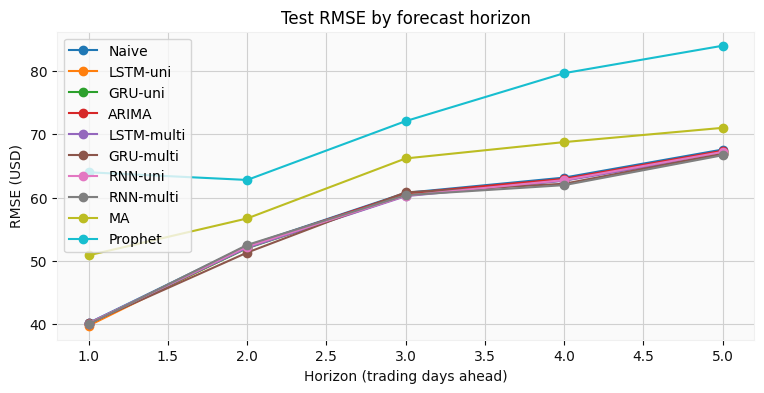

LSTM-uni     vs Naive: mean MAE gain = +0.206 USD | Wilcoxon p = 0.302
GRU-uni      vs Naive: mean MAE gain = +0.100 USD | Wilcoxon p = 0.693
ARIMA        vs Naive: mean MAE gain = +0.053 USD | Wilcoxon p = 0.546
LSTM-multi   vs Naive: mean MAE gain = +0.212 USD | Wilcoxon p = 0.560
GRU-multi    vs Naive: mean MAE gain = +0.366 USD | Wilcoxon p = 0.268
RNN-uni      vs Naive: mean MAE gain = +0.161 USD | Wilcoxon p = 0.789
RNN-multi    vs Naive: mean MAE gain = +0.277 USD | Wilcoxon p = 0.817
MA           vs Naive: mean MAE gain = -6.187 USD | Wilcoxon p = 0.029
Prophet      vs Naive: mean MAE gain = -15.367 USD | Wilcoxon p = 0.001
(paired by forecast origin; 5-day windows overlap in their information, so treat p-values as indicative)


In [ ]:
test_runs = {f: walk_forward(cands[nm], VAL_END, n, desc=nm) for f, nm in best_per_fam.items()}
test_tbl = pd.DataFrame({f"{f} [{best_per_fam[f]}]": metrics(r) for f, r in test_runs.items()}).T
test_tbl["RMSE / Naive"] = test_tbl["RMSE"] / metrics(test_runs["Naive"])["RMSE"]
display(test_tbl.sort_values("RMSE").round(3))

ph = pd.DataFrame({f: np.sqrt(((r.y - r.yhat)**2).groupby(r.h).mean()) for f, r in test_runs.items()})
ph.plot(marker="o", figsize=(9, 4), title="Test RMSE by forecast horizon")
plt.xlabel("Horizon (trading days ahead)"); plt.ylabel("RMSE (USD)"); plt.show()

def mae_by_origin(r): return (r.y - r.yhat).abs().groupby(r["origin"]).mean()
base = mae_by_origin(test_runs["Naive"])
for f, r in test_runs.items():
    if f == "Naive": continue
    d = base - mae_by_origin(r)
    print(f"{f:12s} vs Naive: mean MAE gain = {d.mean():+.3f} USD | Wilcoxon p = {stats.wilcoxon(d).pvalue:.3f}")
print("(paired by forecast origin; 5-day windows overlap in their information, so treat p-values as indicative)")

### 8.3 Prediction vs actual with empirical quantile bands

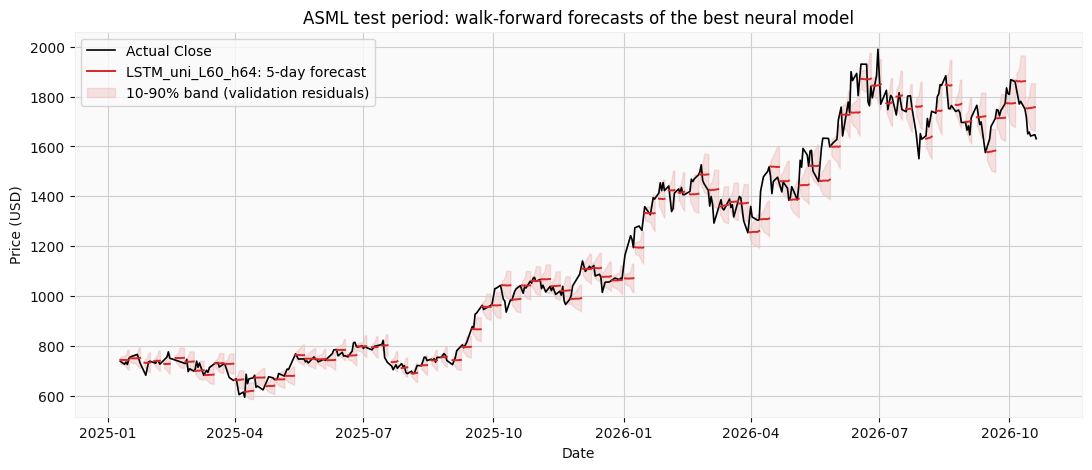

In [ ]:
r = test_runs[dl_fam]
rv = val_runs[dl_best_tag]
lq = np.log(rv.y / rv.yhat).groupby(rv.h).quantile([.1, .9]).unstack()     # residual quantiles from VALIDATION

fig, ax = plt.subplots(figsize=(13, 5))
ts = close.iloc[VAL_END:]
ax.plot(ts.index, ts, color="black", lw=1.2, label="Actual Close")
for i, (o, g) in enumerate(r.groupby("origin")):
    lo, hi = g.yhat * np.exp(lq.loc[g.h, .1].values), g.yhat * np.exp(lq.loc[g.h, .9].values)
    ax.plot(g["date"], g["yhat"], color="tab:red", lw=1.4, label=f"{dl_best_tag}: 5-day forecast" if i == 0 else None)
    ax.fill_between(g["date"], lo, hi, color="tab:red", alpha=.12, label="10-90% band (validation residuals)" if i == 0 else None)
ax.set(title=f"{TICKER} test period: walk-forward forecasts of the best neural model", xlabel="Date", ylabel="Price (USD)")
ax.legend(); plt.show()

## 9. Error Analysis
Residual time series, histogram and ACF, error by VIX regime, and worst forecast origins.

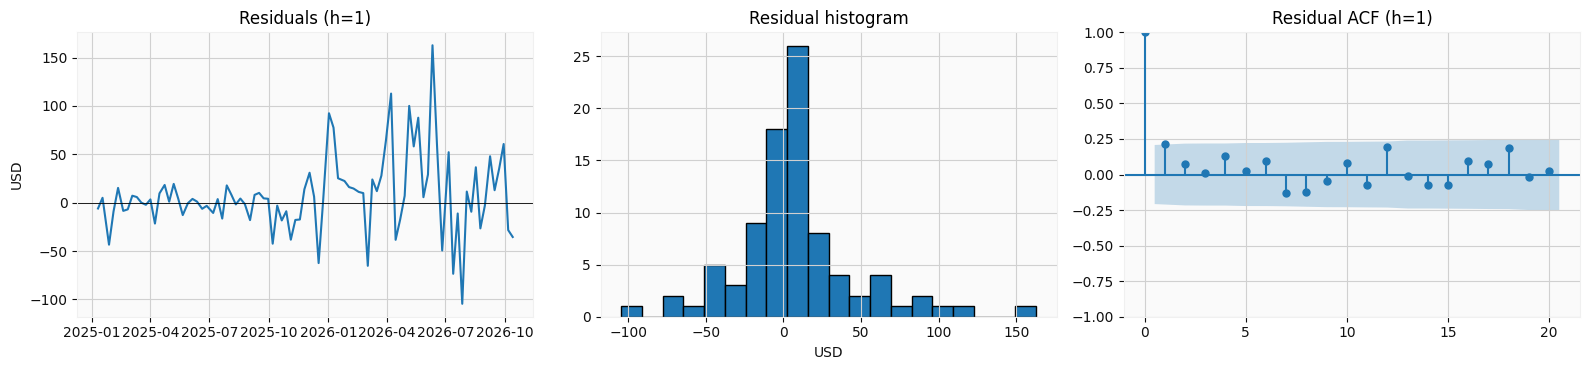

Mean fold RMSE (USD) by market-stress regime (test period):


,Naive,LSTM-uni
regime,,
low VIX,46.36,46.19
mid VIX,40.30,40.23
high VIX,50.37,50.05


Worst forecast origins for the neural model:


,Naive,LSTM-uni,VIX,regime
origin,,,,
2026-04-07,170.47,167.75,25.78,high VIX
2026-07-24,148.91,151.49,18.58,high VIX
2025-12-31,144.38,143.02,14.95,low VIX
2026-05-19,144.80,141.08,18.06,mid VIX
2026-06-10,135.56,133.63,22.22,high VIX


In [ ]:
r1 = r[r.h == 1].set_index("date"); res = r1.y - r1.yhat
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
ax[0].plot(res.index, res); ax[0].axhline(0, c="k", lw=.6); ax[0].set(title="Residuals (h=1)", ylabel="USD")
ax[1].hist(res, bins=20, edgecolor="k"); ax[1].set(title="Residual histogram", xlabel="USD")
plot_acf(res, lags=min(20, len(res)//2 - 1), ax=ax[2]); ax[2].set_title("Residual ACF (h=1)")
plt.tight_layout(); plt.show()

vix = ext["^VIX"].reindex(df.index).ffill()
fr = pd.DataFrame({"Naive": fold_rmse(test_runs["Naive"]), dl_fam: fold_rmse(r)})
fr["VIX"] = vix.reindex(fr.index).values
fr["regime"] = pd.qcut(fr["VIX"].rank(method="first"), 3, labels=["low VIX", "mid VIX", "high VIX"])   # terciles
print("Mean fold RMSE (USD) by market-stress regime (test period):")
display(fr.groupby("regime", observed=True)[["Naive", dl_fam]].mean().round(2))
print("Worst forecast origins for the neural model:")
display(fr.sort_values(dl_fam, ascending=False).head(5).round(2))

### 9.1 Walk-forward validation diagram and aggregated performance

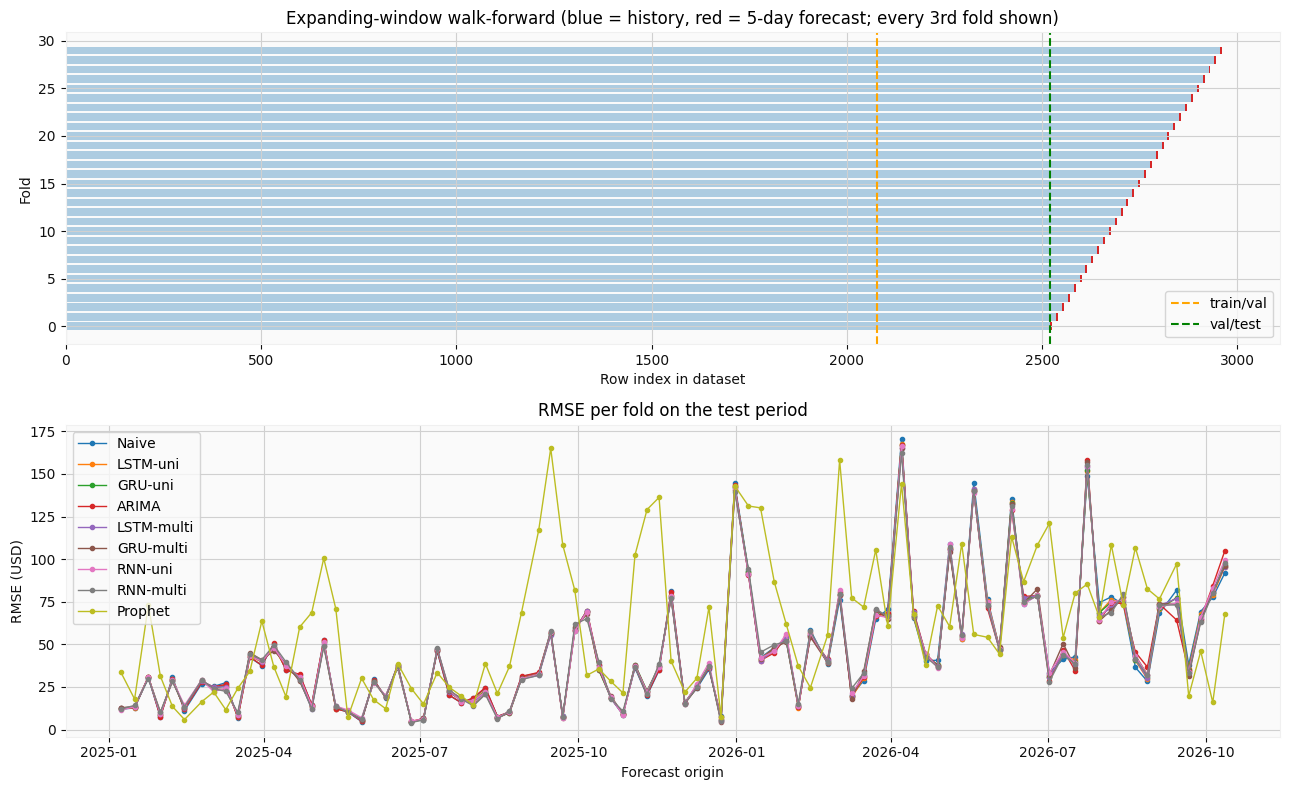

Aggregated test RMSE (USD): {'Naive': np.float64(57.63), 'LSTM-uni': np.float64(57.26), 'GRU-uni': np.float64(57.27), 'ARIMA': np.float64(57.48), 'LSTM-multi': np.float64(57.18), 'GRU-multi': np.float64(57.07), 'RNN-uni': np.float64(57.33), 'RNN-multi': np.float64(57.08), 'MA': np.float64(63.17), 'Prophet': np.float64(72.96)}


In [ ]:
origins = list(range(VAL_END, n - H_MAIN + 1, STEP))
fig, (a1, a2) = plt.subplots(2, 1, figsize=(13, 8))
for i, t in enumerate(origins[::3]):
    a1.barh(i, t, color="tab:blue", alpha=.35); a1.barh(i, H_MAIN, left=t, color="tab:red")
a1.axvline(TRAIN_END, c="orange", ls="--", label="train/val"); a1.axvline(VAL_END, c="green", ls="--", label="val/test")
a1.set(title="Expanding-window walk-forward (blue = history, red = 5-day forecast; every 3rd fold shown)",
       xlabel="Row index in dataset", ylabel="Fold"); a1.legend(loc="lower right")
for f, rr in test_runs.items():
    if f.startswith("MA"): continue
    fr_ = fold_rmse(rr); a2.plot(fr_.index, fr_.values, marker=".", lw=1, label=f)
a2.set(title="RMSE per fold on the test period", xlabel="Forecast origin", ylabel="RMSE (USD)"); a2.legend()
plt.tight_layout(); plt.show()
print("Aggregated test RMSE (USD):", {f: round(metrics(rr)['RMSE'], 2) for f, rr in test_runs.items()})

## 10. Conclusions and Lessons Learned

# Executive summary

> **Bottom line:** no model significantly beat the naïve baseline. The best neural model, `LSTM_uni_L60_h64`, reached a test RMSE of **57.26 USD** vs **57.63 USD** for naïve (ratio **0.994**, Wilcoxon **p = 0.302**).

---

### Task
Forecast ASML's Close for the next **5 trading days** with RNN, LSTM and GRU (univariate and multivariate) against naïve and moving-average baselines, with ARIMA and Prophet as optional references.
Data: **2,967 trading days** (2015-01-02 to 2026-10-20).

### Validation protocol
Chronological 70/15/15 split. The scaler and target scale are fit on training data only. Early stopping, scheduling and all model choices use validation only. The test set is used once, with rolling-origin evaluation (new origin every 5 days).

| Split | Period | Role |
|:--|:--|:--|
| Train (70%) | 2015-01-02 → 2023-03-31 | fit weights, scaler, target scale |
| Validation (15%) | 2023-04-03 → 2025-01-08 | early stopping, scheduling, model choice |
| Test (15%) | 2025-01-10 → 2026-10-20 | used once, 89 origins |

### Best model

| | |
|:--|:--|
| **Model** | `LSTM_uni_L60_h64` (univariate, 60-day lookback, 64 hidden units) |
| **Test RMSE** | 57.26 USD |
| **Naïve test RMSE** | 57.63 USD |
| **Ratio (model / naïve)** | **0.994** |
| **Wilcoxon p** | 0.302 → *not significant* |
| **Validation** | naïve was the best method overall (RMSE 31.43 USD) |

### Test results (rolling origin, 89 origins)

| Method | RMSE (USD) | RMSE / Naïve | Wilcoxon p vs naïve |
|:--|--:|--:|--:|
| GRU-multi `GRU_multi_L60_h32` | 57.073 | 0.990 | 0.268 |
| RNN-multi | 57.079 | 0.991 | 0.817 |
| LSTM-multi | 57.184 | 0.992 | 0.560 |
| **LSTM-uni** (chosen on validation) | **57.260** | **0.994** | **0.302** |
| GRU-uni | 57.274 | 0.994 | 0.693 |
| RNN-uni | 57.327 | 0.995 | 0.789 |
| ARIMA | 57.484 | 0.998 | 0.546 |
| Naïve | 57.626 | 1.000 | n/a |
| MA5 | 63.166 | 1.096 | 0.029 |
| Prophet | 72.959 | 1.266 | 0.001 |

*The ratios of all neural models and ARIMA are within 1% of naïve. MA5 and Prophet are significantly worse.*

### What worked
- The **leak-free pipeline** produced stable, well-behaved models: every neural network and ARIMA landed within 1% of naïve (ratios 0.990 to 0.998).
- **Multivariate vs univariate:** multivariate models were nominally ahead (0.990 to 0.992 vs 0.994 to 0.995). GRU-multi was nominally best on test (RMSE 57.07 USD, ratio 0.990, p = 0.268, directional accuracy 56.2%).
- **Best configuration by validation loss:** GRU-multi with lookback 60 and 64 hidden units.
- Differences between architectures, lookbacks and hidden sizes were **very small** (validation loss 1.135 to 1.152).

### What failed
- **No model significantly beat naïve** (all neural/ARIMA p ≥ 0.27; mean MAE gain ≤ 0.4 USD).
- **The edge fades with the horizon** (validation, ratio vs naïve):

  | Horizon | 1 day | 3 days | 5 days |
  |:--|--:|--:|--:|
  | Ratio | 0.993 | 1.000 | 1.009 |

- **MA5** (ratio 1.096, p = 0.029) and **Prophet** (ratio 1.266, p = 0.001) were significantly worse than naïve.
- **Errors peak in high-VIX periods**, but the network barely helps in any regime (mean fold RMSE, USD):

  | Regime | Naïve | LSTM-uni |
  |:--|--:|--:|
  | Low VIX | 46.36 | 46.19 |
  | Mid VIX | 40.30 | 40.23 |
  | High VIX | 50.37 | 50.05 |

- On the worst forecast origins, the network's errors were almost identical to naïve's, so it behaves like a naïve forecaster.

### Limitations
- Near-random-walk prices and regime shifts
- Single ticker
- Overlapping 5-day windows
- Fixed network weights during walk-forward
- No transaction costs
- The test period was more volatile than validation (naïve MAPE 3.38% vs 2.53%), and with 89 origins small differences cannot be separated from noise

### Future work
- Periodic retraining in walk-forward
- Probabilistic (quantile) loss
- More tickers
- Attention / Transformer models

## 11. Reproducibility Notes and Deliverables
### 11.1 Saved best model, config and reload-and-predict utility

In [ ]:
shutil.copy(f"ckpt/{dl_best_tag}.pt", "best_model.pt")
json.dump(dict(ticker=TICKER, horizon=H_MAIN, seed=SEED, device=device,
               data_range=[str(df.index[0].date()), str(df.index[-1].date())],
               best_neural_on_validation=dl_best_tag, best_per_family=best_per_fam,
               val_metrics=val_tbl.loc[list(best_per_fam.values())].round(4).to_dict("index"),
               test_metrics=test_tbl.round(4).to_dict("index")),
          open("best_model_config.json", "w"), indent=2)

def predict_next(path="best_model.pt", data=None, ext_data=None):
    """Reload saved weights + scaler and forecast the next H closes from the last L days (L=60 for the default model)."""
    ck = torch.load(path, map_location=device, weights_only=False); c = ck["cfg"]
    m = ARCH[c["cell"]](len(c["cols"]), c["hidden"], c["layers"], c["dropout"], c["H"]).to(device)
    m.load_state_dict(ck["state"]); m.eval()
    d = df if data is None else data
    Fn = build_features(d, ext if ext_data is None else ext_data)[c["cols"]].fillna(0).values
    Xs = ((Fn - np.array(c["mean"])) / np.array(c["scale"])).astype(np.float32)
    with torch.no_grad():
        out = m(torch.from_numpy(Xs[-c["L"]:]).unsqueeze(0).to(device)).cpu().numpy()[0] * c["ysd"]
    dates = pd.bdate_range(d.index[-1] + pd.Timedelta(days=1), periods=c["H"])
    print(f"model={c['tag']} | lookback used = last {c['L']} trading days")
    return pd.Series(d["Close"].iloc[-1] * np.exp(out), index=dates, name="forecast_close")

predict_next()

model=LSTM_uni_L60_h64 | lookback used = last 60 trading days


,forecast_close
2026-10-21,1633.044784
2026-10-22,1633.342428
2026-10-23,1635.287513
2026-10-26,1636.151865
2026-10-27,1639.804464


### 11.2 Environment and requirements

In [ ]:
import sys, platform
print("Python", sys.version.split()[0], "|", platform.platform())
print("torch", torch.__version__, "| CUDA", torch.version.cuda, "| cuDNN", torch.backends.cudnn.version(), "| seed", SEED)
!pip freeze | grep -iE "^(torch|numpy|pandas|scikit-learn|scipy|statsmodels|prophet|mplfinance|yfinance|matplotlib|tqdm)==" > requirements.txt
!cat requirements.txt

Python 3.13.15 | Linux-6.6.122+-x86_64-with-glibc2.39
torch 2.11.0+cu130 | CUDA 13.0 | cuDNN 92700 | seed 42
matplotlib==3.10.0
mplfinance==0.12.10b0
numpy==2.1.3
pandas==2.2.3
prophet==1.5.0
scikit-learn==1.6.1
scipy==1.16.3
statsmodels==0.15.0
torch==2.11.0+cu130
tqdm==4.67.3
yfinance==0.2.66
